# Where the thresholds come from

Every speed and distance threshold in `possession/config.py` is a football or physics prior. This
notebook checks each one against the **unlabelled** tracking of the match, so you can see that the
numbers were not picked at random and were not tuned on any ground truth.

**What this notebook never reads:** no ground truth of any kind (public or private), no event data
and no hand labels. Its inputs are the parsed tracking (`cache/atd_tactical.npz`, built by
`possession/parse_atd.py`), the homography and the Smart Tagging, which are the same inputs the
pipeline uses.

Where the tracking cannot tell us the answer by itself, we use **physical anchors**: frames whose
state is fixed by the Laws of the Game or by physics, not by anyone's judgement.
- *Dead anchor:* 3 to 15 s after the ball has left the pitch, while it has not yet come back in.
  By Law 9 the ball is out of play for that whole stretch.
- *Alive anchor:* the ball is inside the pitch and travelling faster than any player can run
  (> 8 m/s, see section 2). Only a ball in play is struck that hard.

Run it from the repository root after `python possession/run.py` has built the cache (or let the
first cell build it).

In [1]:
import os, sys, warnings
import numpy as np
import matplotlib.pyplot as plt

HERE = os.path.abspath('')
PKG = HERE if os.path.isfile(os.path.join(HERE, 'config.py')) else os.path.join(HERE, 'possession')
if os.path.basename(HERE) == 'notebooks':
    PKG = os.path.dirname(HERE)
sys.path.insert(0, PKG)

from common import games
import config, parse_atd, features, model

atd = parse_atd.load()          # parses the raw ATD once (~1 min) if the cache is missing
f = features.build(atd)
n = len(atd['ball'])
graded = np.zeros(n, bool)
for _, a, b in games.half_video_blocks(games.GAME):
    graded[a:b + 1] = True
FPS = config.FPS
print(f'{n} frames, {graded.sum()} graded, ball seen on {f["seen"][graded].mean():.1%} of graded frames')
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.grid': True, 'grid.alpha': .3})

199319 frames, 158857 graded, ball seen on 59.3% of graded frames


## 1. Anchors

In [2]:
def runs(mask):
    d = np.diff(np.concatenate(([0], mask.astype(np.int8), [0])))
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)

seen, out = f['seen'], f['out']
ball_speed = np.nan_to_num(f['ball_speed'], nan=0.0)
squad = f['squad_speed']

def dead_anchor(t0=3, t1=15):
    m = np.zeros(n, bool)
    for a, b in zip(*runs(out & graded)):
        t = b
        while t < n and t < a + t1 * FPS and (out[t] or not seen[t]):
            t += 1
        m[a + t0 * FPS:t] = True
    return m & graded

def alive_anchor(v=8.0):
    return graded & seen & ~out & (ball_speed > v)

dead, alive = dead_anchor(), alive_anchor()
print(f'ball leaves the pitch {len(runs(out & graded)[0])} times')
print(f'dead anchor  {dead.sum():6d} frames ({dead.sum()/FPS/60:.1f} min)')
print(f'alive anchor {alive.sum():6d} frames ({alive.sum()/FPS/60:.1f} min)')

ball leaves the pitch 71 times
dead anchor    4957 frames (3.3 min)
alive anchor  29310 frames (19.5 min)


## 2. Individual player speed → `FAST_BALL_MS = 8.0`

A ball moving faster than a player can run is not being carried. It is in flight after a pass,
shot or clearance. Below we look at the provider's per-player speed channel.

player speed percentiles 50/90/99/99.9 (m/s): [1.41 3.85 6.44 8.1 ]


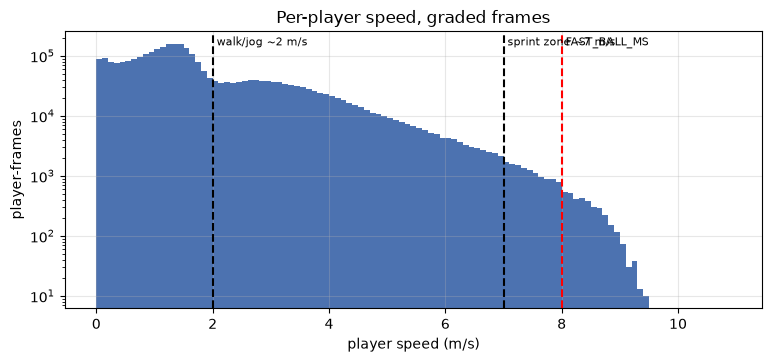

share of player-frames above FAST_BALL_MS: 0.1184%


In [3]:
sp = atd['speed'][graded]
sp = sp[~np.isnan(sp)]
q = np.percentile(sp, [50, 90, 99, 99.9])
print('player speed percentiles 50/90/99/99.9 (m/s):', q.round(2))
fig, ax = plt.subplots()
ax.hist(sp, bins=np.arange(0, 11, 0.1), color='#4c72b0')
for x, lab in [(2.0, 'walk/jog ~2 m/s'), (7.0, 'sprint zone ~7 m/s'), (config.FAST_BALL_MS, 'FAST_BALL_MS')]:
    ax.axvline(x, ls='--', c='k' if x != config.FAST_BALL_MS else 'r'); ax.text(x, ax.get_ylim()[1]*.9, ' ' + lab, fontsize=8)
ax.set_yscale('log'); ax.set_xlabel('player speed (m/s)'); ax.set_ylabel('player-frames')
ax.set_title('Per-player speed, graded frames')
plt.show()
print(f'share of player-frames above FAST_BALL_MS: {(sp > config.FAST_BALL_MS).mean():.4%}')

Players almost never exceed 8 m/s: it is above the 99.9th percentile of player speed. So a ball
above 8 m/s is moving faster than anyone could dribble it. That makes it "travelling, not under
control" (a touch then counts only `W_TOUCH_FAST`) and "in play" (`W_FAST_BALL_ALIVE`).

## 3. Ball speed → `STILL_BALL_MS = 1.0` and `FAST_BALL_MS = 8.0`

ball speed percentiles 10/25/50/75/90/99: [ 1.03  2.39  5.1   9.53 14.29 24.56]


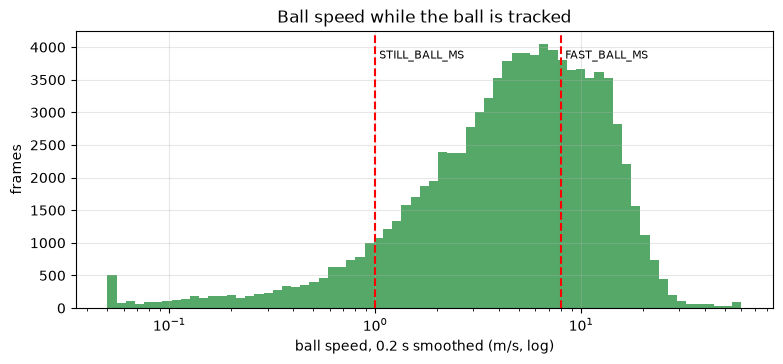

below STILL: 9.7%   above FAST: 31.6%


In [4]:
bs = f['ball_speed'][graded & seen]
bs = bs[~np.isnan(bs)]
print('ball speed percentiles 10/25/50/75/90/99:', np.percentile(bs, [10, 25, 50, 75, 90, 99]).round(2))
fig, ax = plt.subplots()
ax.hist(np.clip(bs, 0.05, 60), bins=np.logspace(np.log10(0.05), np.log10(60), 70), color='#55a868')
ax.set_xscale('log')
for x, lab in [(config.STILL_BALL_MS, 'STILL_BALL_MS'), (config.FAST_BALL_MS, 'FAST_BALL_MS')]:
    ax.axvline(x, ls='--', c='r'); ax.text(x, ax.get_ylim()[1]*.9, ' ' + lab, fontsize=8)
ax.set_xlabel('ball speed, 0.2 s smoothed (m/s, log)'); ax.set_ylabel('frames')
ax.set_title('Ball speed while the ball is tracked')
plt.show()
print(f'below STILL: {(bs < config.STILL_BALL_MS).mean():.1%}   above FAST: {(bs > config.FAST_BALL_MS).mean():.1%}')

On a log scale the ball speed has a single mode, around 5–7 m/s: the ball at a player's feet or
in short passes. There is no natural gap to cut at, so both thresholds come from physics, not from
the histogram's shape:
- 8 m/s is the player-speed bound from §2. About a third of tracked frames lie above it: passes,
  shots and clearances.
- 1 m/s is slower than a slow walk (~1.4 m/s), so the ball is practically stationary. That is the
  slowest ~10% tail. When nobody is near the ball as well, it is a placed ball, a restart about to
  happen (`W_STILL_BALL`, weight only 0.5).

## 4. Squad speed → `WALK_SPEED_MS` (v1 = 1.8, v2 = 1.6)

`squad_speed` is the mean speed of all tracked players, averaged over 2 s. Players walk back and
regroup during a stoppage, and run while the ball is alive. The open question is where "walking
squad" starts.

squad speed percentiles 10/25/50/75/90: [0.71 1.04 1.54 2.31 3.06]


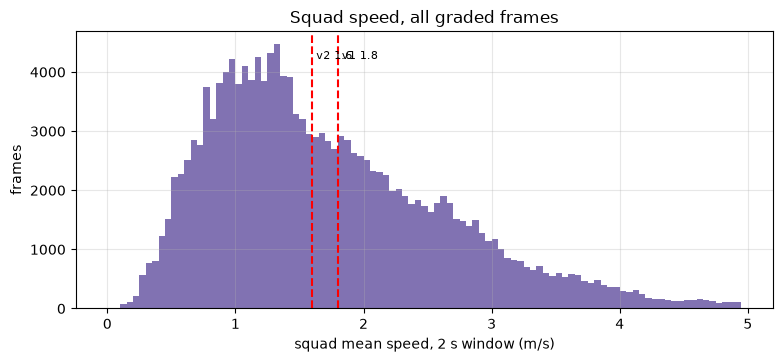

share of graded frames with squad speed < 1.8: 59.4%
share of graded frames with squad speed < 1.6: 52.3%


In [5]:
sq = squad[graded]; sq = sq[~np.isnan(sq)]
print('squad speed percentiles 10/25/50/75/90:', np.percentile(sq, [10, 25, 50, 75, 90]).round(2))
fig, ax = plt.subplots()
ax.hist(sq, bins=np.arange(0, 5, 0.05), color='#8172b2')
for x, lab in [(1.8, 'v1 1.8'), (1.6, 'v2 1.6')]:
    ax.axvline(x, ls='--', c='r'); ax.text(x, ax.get_ylim()[1]*.9, ' ' + lab, fontsize=8)
ax.set_xlabel('squad mean speed, 2 s window (m/s)'); ax.set_ylabel('frames'); ax.set_title('Squad speed, all graded frames')
plt.show()
for thr in (1.8, 1.6):
    print(f'share of graded frames with squad speed < {thr}: {(sq < thr).mean():.1%}')

The squad-speed distribution has **one** broad mode, near 1.3 m/s, and no valley. A threshold
chosen from its shape alone (a quantile, or Otsu) would be arbitrary, and v1's 1.8 m/s already
marks most of the match "slow". That was our first hint that v1 over-predicts D (55% of graded
frames). The anchors below separate the two populations without any labels.

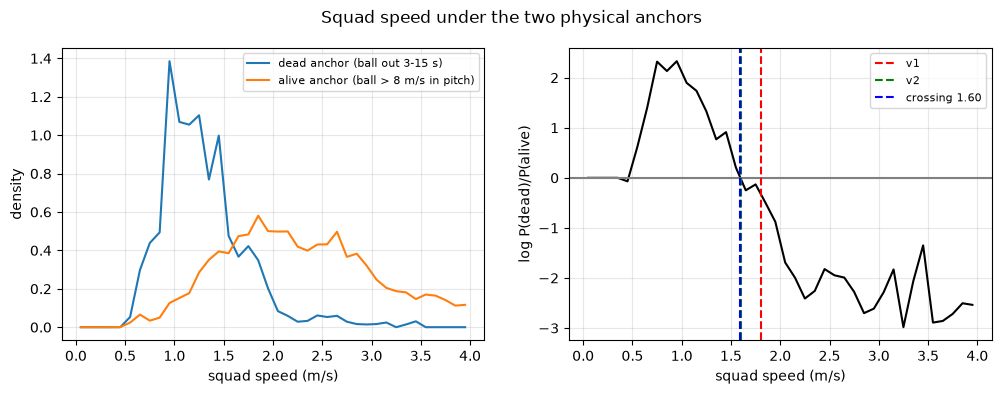

log-likelihood ratio crosses zero at 1.60 m/s


In [6]:
bins = np.arange(0.0, 4.01, 0.1)
centre = (bins[:-1] + bins[1:]) / 2
def llr_curve(dead_m, alive_m):
    hd, _ = np.histogram(squad[dead_m & ~np.isnan(squad)], bins, density=True)
    ha, _ = np.histogram(squad[alive_m & ~np.isnan(squad)], bins, density=True)
    return np.log((hd + 1e-2) / (ha + 1e-2)), hd, ha

def crossing(llr):
    # first sign change from + (dead) to - (alive) going up in speed, linearly interpolated
    for i in range(len(llr) - 1):
        if llr[i] > 0 >= llr[i + 1]:
            return centre[i] + (centre[i + 1] - centre[i]) * llr[i] / (llr[i] - llr[i + 1])
    return np.nan

llr, hd, ha = llr_curve(dead, alive)
x0 = crossing(llr)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(centre, hd, label='dead anchor (ball out 3-15 s)'); a1.plot(centre, ha, label='alive anchor (ball > 8 m/s in pitch)')
a1.set_xlabel('squad speed (m/s)'); a1.set_ylabel('density'); a1.legend(fontsize=8)
a2.plot(centre, llr, c='k'); a2.axhline(0, c='grey')
for x, lab, c in [(1.8, 'v1', 'r'), (1.6, 'v2', 'g'), (x0, f'crossing {x0:.2f}', 'b')]:
    a2.axvline(x, ls='--', c=c, label=lab)
a2.set_xlabel('squad speed (m/s)'); a2.set_ylabel('log P(dead)/P(alive)'); a2.legend(fontsize=8)
fig.suptitle('Squad speed under the two physical anchors'); plt.show()
print(f'log-likelihood ratio crosses zero at {x0:.2f} m/s')

### Is the crossing robust to how the anchors are defined?

In [7]:
rows = []
for t0, t1 in [(2, 10), (3, 15), (5, 20)]:
    for v in (6.0, 8.0, 10.0):
        c = crossing(llr_curve(dead_anchor(t0, t1), alive_anchor(v))[0])
        rows.append((t0, t1, v, c))
        print(f'dead = {t0:>2}-{t1:<2} s after out | alive = ball > {v:>4} m/s  ->  crossing {c:.2f} m/s')
cs = np.array([r[3] for r in rows])
print(f'\nrange over 9 anchor definitions: {np.nanmin(cs):.2f} - {np.nanmax(cs):.2f} m/s (median {np.nanmedian(cs):.2f})')

dead =  2-10 s after out | alive = ball >  6.0 m/s  ->  crossing 1.79 m/s
dead =  2-10 s after out | alive = ball >  8.0 m/s  ->  crossing 1.78 m/s
dead =  2-10 s after out | alive = ball > 10.0 m/s  ->  crossing 1.76 m/s
dead =  3-15 s after out | alive = ball >  6.0 m/s  ->  crossing 1.60 m/s
dead =  3-15 s after out | alive = ball >  8.0 m/s  ->  crossing 1.60 m/s
dead =  3-15 s after out | alive = ball > 10.0 m/s  ->  crossing 1.60 m/s
dead =  5-20 s after out | alive = ball >  6.0 m/s  ->  crossing 1.58 m/s
dead =  5-20 s after out | alive = ball >  8.0 m/s  ->  crossing 1.57 m/s
dead =  5-20 s after out | alive = ball > 10.0 m/s  ->  crossing 1.58 m/s

range over 9 anchor definitions: 1.57 - 1.79 m/s (median 1.60)


The crossing depends on one thing: whether the dead anchor includes the **first 3 seconds** after
the ball goes out.
- With a 2–10 s window, the crossing is about 1.78 m/s, close to v1's 1.8.
- Once those first seconds are excluded (3–15 s or 5–20 s), it settles at **1.57–1.60 m/s**,
  whatever the alive definition.

Those first seconds are players still decelerating from the action that put the ball out. That is
the transition into a stoppage, not the stoppage itself, so it mixes the two populations we are
trying to separate. **v2 uses 1.6 m/s**, the crossing of the central definition and the median of
all nine. v1's 1.8 m/s matches the contaminated window.

Two caveats, both stated in the technical document:
- The dead anchor is small, a few thousand frames from the throw-ins, goal kicks and corners where
  the tracker still sees the ball outside.
- The alive anchor over-represents intense moments.

So we take only the *location* of the crossing from this, not a full likelihood model, and keep
`W_SLOW` as the prior weight.

### The v2 gate: is a slow squad around a moving ball a stoppage?

In [8]:
in_play = graded & seen & ~out & (ball_speed >= config.STILL_BALL_MS)
slow = graded & (np.nan_to_num(squad, nan=9) < 1.6)
print(f'graded frames with a slow squad (< 1.6 m/s):           {slow.sum():6d}')
print(f'  ...of which the ball is visibly moving inside the pitch: {(slow & in_play).sum():6d} ({(slow & in_play).sum()/slow.sum():.0%})')
moving = (graded & seen & ~out & (ball_speed > 3.0))
print(f'squad speed when ball moves 3-8 m/s in pitch, median: {np.nanmedian(squad[moving & (ball_speed < 8)]):.2f} m/s')

graded frames with a slow squad (< 1.6 m/s):            82857
  ...of which the ball is visibly moving inside the pitch:  20788 (25%)
squad speed when ball moves 3-8 m/s in pitch, median: 2.19 m/s


A large share of the "slow squad" frames have a ball that is visibly being played inside the pitch:
slow circulation at the back or a goalkeeper in possession. v2 halves the slow-squad dead evidence
on those frames (`SLOW_IN_PLAY_FACTOR = 0.5`) and keeps it at full weight when the ball is missing,
still or out.

## 5. Touch radius → `TOUCH_RADIUS_M = 2.0`, `TOUCH_MARGIN_M = 0.75`

nearest-player distance when the ball moves < 5 m/s, percentiles 25/50/75/90: [0.61 1.14 2.27 5.26]


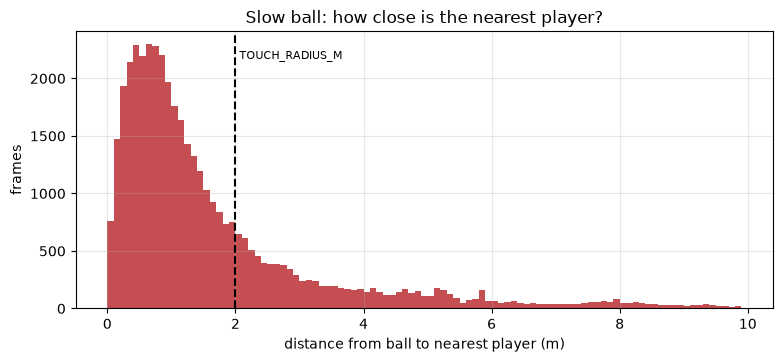

within 2 m: share where the two teams are within 0.75 m of each other (contested): 7.3%


In [9]:
near = np.minimum(f['d_home'], f['d_away'])
ctrl = graded & seen & ~out & (ball_speed < 5) & np.isfinite(near)
d = near[ctrl]
print('nearest-player distance when the ball moves < 5 m/s, percentiles 25/50/75/90:', np.percentile(d, [25, 50, 75, 90]).round(2))
fig, ax = plt.subplots()
ax.hist(np.clip(d, 0, 10), bins=np.arange(0, 10, 0.1), color='#c44e52')
ax.axvline(config.TOUCH_RADIUS_M, ls='--', c='k'); ax.text(config.TOUCH_RADIUS_M, ax.get_ylim()[1]*.9, ' TOUCH_RADIUS_M', fontsize=8)
ax.set_xlabel('distance from ball to nearest player (m)'); ax.set_ylabel('frames'); ax.set_title('Slow ball: how close is the nearest player?')
plt.show()
with np.errstate(invalid='ignore'):
    gap = np.abs(f['d_home'] - f['d_away'])[ctrl & (near < 2)]
gap = gap[np.isfinite(gap)]
print(f'within 2 m: share where the two teams are within {config.TOUCH_MARGIN_M} m of each other (contested): {(gap <= config.TOUCH_MARGIN_M).mean():.1%}')

When the ball is slow enough to be controlled, the nearest player's distance peaks around 0.5 to
1 m. Some of that is the ball tracker and the player tracker (body centre) disagreeing, and some is
a stride. 2 m is about one step plus that offset, and it sits past the mode, so it keeps the
controlled frames. The 0.75 m margin removes frames where both teams are equally close: a
challenge, which per CHALLENGE.md must not change possession on its own.

## 6. Out of play → `OUT_MARGIN_M = 0.5`

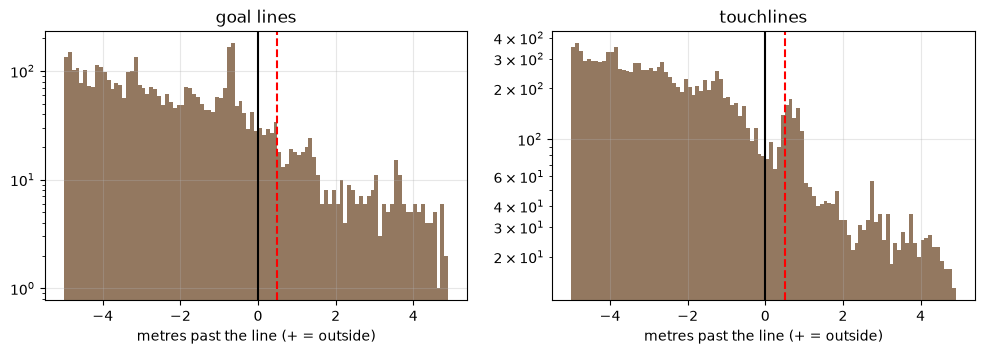

ball beyond the lines by > 0.5 m on 3339 graded frames


In [10]:
L, W = config.PITCH
bx, by = atd['ball'][graded & seen, 0], atd['ball'][graded & seen, 1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
edge = np.concatenate([-bx[bx < 5], bx[bx > L - 5] - L])        # signed distance past the goal lines
side = np.concatenate([-by[by < 5], by[by > W - 5] - W])        # ... past the touchlines
for a, v, t in [(a1, edge, 'goal lines'), (a2, side, 'touchlines')]:
    a.hist(np.clip(v, -5, 5), bins=np.arange(-5, 5, 0.1), color='#937860')
    a.axvline(config.OUT_MARGIN_M, c='r', ls='--'); a.axvline(0, c='k')
    a.set_xlabel('metres past the line (+ = outside)'); a.set_title(t); a.set_yscale('log')
plt.show()
print(f'ball beyond the lines by > {config.OUT_MARGIN_M} m on {f["out"][graded].sum()} graded frames')

The density falls sharply across the first half-metre past each line, then continues as a long
flat tail. That tail is the ball really out: being retrieved, or a throw-in being taken. The ball
radius is 0.11 m, and position noise smears the edge by a few decimetres. 0.5 m clears both, so a
ball rolling along the line is not called out, and it is still small enough to keep almost all of
the out-of-play tail.

## 7. Camera pan → `STILL_CAMERA_MS = 0.5`

camera-centre speed percentiles 25/50/75/90 (m/s): [0.06 0.17 1.39 2.97]


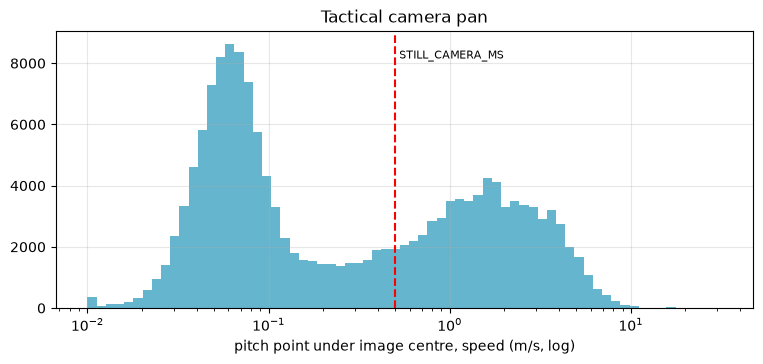

In [11]:
pan = f['camera_pan'][graded]; pan = pan[~np.isnan(pan)]
print('camera-centre speed percentiles 25/50/75/90 (m/s):', np.percentile(pan, [25, 50, 75, 90]).round(2))
fig, ax = plt.subplots()
ax.hist(np.clip(pan, 0.01, 30), bins=np.logspace(-2, 1.5, 70), color='#64b5cd'); ax.set_xscale('log')
ax.axvline(config.STILL_CAMERA_MS, c='r', ls='--'); ax.text(config.STILL_CAMERA_MS, ax.get_ylim()[1]*.9, ' STILL_CAMERA_MS', fontsize=8)
ax.set_xlabel('pitch point under image centre, speed (m/s, log)'); ax.set_title('Tactical camera pan'); plt.show()

The camera-pan distribution is clearly bimodal: a "camera parked" mode around 0.06 m/s, and a
"following play" mode around 1–3 m/s. 0.5 m/s sits at the upper edge of the valley between them. It is a weak cue
(`W_STILL_CAMERA = 0.2`), because the camera also parks during slow build-up.

## 8. Ball-missing gaps → why interpolation was dropped, and `MISSING_HARD_S = 2.0`

In [12]:
s, e = runs(graded & ~seen)
L_s = (e - s) / FPS
print(f'{len(s)} gaps; length percentiles 10/50/90 (s): {np.percentile(L_s, [10, 50, 90]).round(1)}')
print(f'gaps <= 1 s: {(L_s <= 1).sum()}   gaps <= 2 s: {(L_s <= 2).sum()}   frames in gaps >= 2 s: {((e - s)[L_s >= 2]).sum() / graded.sum():.1%} of graded')
sq_gap = [np.nanmean(squad[a:b]) for a, b in zip(s, e) if b - a >= 2 * FPS]
print(f'median squad speed inside gaps >= 2 s: {np.nanmedian(sq_gap):.2f} m/s (dead-anchor median {np.nanmedian(squad[dead]):.2f}, alive-anchor median {np.nanmedian(squad[alive]):.2f})')

150 gaps; length percentiles 10/50/90 (s): [ 0.5 10.7 33.8]
gaps <= 1 s: 17   gaps <= 2 s: 17   frames in gaps >= 2 s: 40.6% of graded
median squad speed inside gaps >= 2 s: 1.25 m/s (dead-anchor median 1.21, alive-anchor median 2.26)


The tracker does not drop the ball for a frame or two here and there. It loses it in long gaps,
with a median of about 10 s. Interpolating short gaps (an idea for v2) would therefore change
almost nothing, so we dropped it. The squad inside those gaps moves at dead-anchor speed. That is
why a gap of 2 s or more counts as a **hard** stoppage cue in v2 (`merge_unsupported_dead`).

## 9. Is the predicted dead-ball share plausible? (label-free check)

Football prior: elite matches have about 52–60 minutes of effective playing time. The graded
frames contain both halves from kickoff (plus the 2,934 frames before the second-half kickoff,
which are all dead), up to the final whistle.

In [13]:
k2 = 113742
play_frames = graded.sum() - (k2 - 110808)
clock_min = play_frames / FPS / 60
lo = (play_frames - 60 * 60 * FPS + (k2 - 110808)) / graded.sum()
hi = (play_frames - 52 * 60 * FPS + (k2 - 110808)) / graded.sum()
print(f'clock time between kickoffs and whistles: {clock_min:.1f} min')
print(f'plausible dead-ball share of graded frames: {lo:.0%} - {hi:.0%}')
for v in ('v1', 'v2'):
    config.select(v)
    lab = model.decode(features.build(atd), games.half_video_blocks(games.GAME))
    print(f'{v}: predicted D share {np.mean(lab[graded] == "D"):.1%}')

clock time between kickoffs and whistles: 103.9 min
plausible dead-ball share of graded frames: 43% - 51%


v1: predicted D share 55.1%


v2: predicted D share 47.7%


## Summary

| threshold | value | evidence in this notebook |
|---|---|---|
| `FAST_BALL_MS` | 8.0 m/s | above the 99.9th percentile of player speed: faster than any player can carry the ball (§2) |
| `STILL_BALL_MS` | 1.0 m/s | slower than a slow walk; the slowest ~10% of ball speeds (§3) |
| `WALK_SPEED_MS` | v1 1.8 → **v2 1.6** m/s | zero crossing of the dead/alive log-likelihood ratio from physical anchors: 1.57–1.60 once the deceleration seconds are excluded, 1.6 = median of 9 definitions (§4) |
| `SLOW_IN_PLAY_FACTOR` | v2 0.5 | many slow-squad frames have a ball visibly in play (§4) |
| `TOUCH_RADIUS_M` / `TOUCH_MARGIN_M` | 2.0 / 0.75 m | past the mode of nearest-player distance for a controllable ball; the margin removes contested frames (§5) |
| `OUT_MARGIN_M` | 0.5 m | past ball radius plus tracker noise at the lines (§6) |
| `STILL_CAMERA_MS` | 0.5 m/s | valley between the "camera parked" and "following play" modes (§7) |
| `MISSING_HARD_S` | 2.0 s | gaps are long (median ~10 s) and the squad inside them moves at dead-anchor speed (§8) |

v1's D share falls outside the label-free plausible band; v2's falls inside it (§9). None of the
values above was fitted to or selected on any ground truth.